# TRABAJO FIN DE GRADO: Detección de TEA mediante sistemas de IA

#### **Estudiante**: Ángel Vilariño García
#### **Dirección**: Verónica Bolón Canedo y Brais Cancela Barizo

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from math import pi
import ast

import json
import pyreadstat
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_curve, auc, ConfusionMatrixDisplay, classification_report
from hyperopt import fmin, tpe, hp, Trials, STATUS_OK
from IPython.display import display

# 1. CARGA DE VARIABLES (TOP 20 ÉTICO) Y DATOS
with open('resultados/mejores_variables.json', 'r') as f:
    features_finales = json.load(f)

df, meta = pyreadstat.read_sav('TEA_1.sav')

X_opt = df[features_finales]
y_opt = df['Diag_primario']

# 2. PREPROCESAMIENTO COHERENTE (KNN + SCALER)
imputador_knn = KNNImputer(n_neighbors=5)
escalador = StandardScaler()

X_proc = escalador.fit_transform(imputador_knn.fit_transform(X_opt))

# 3. CONFIGURACIÓN DE VALIDACIÓN Y MÉTRICAS
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

metrics_dict = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

print(f"Configuración lista: {X_proc.shape[0]} sujetos y {X_proc.shape[1]} variables.")

Configuración lista: 209 sujetos y 20 variables.


In [12]:
# OPTIMIZACIÓN SISTEMÁTICA (GRID SEARCH)

param_grids = {
    'SVM': {
        'model': SVC(random_state=42, probability=True),
        'params': {
            'C': [0.1, 1, 10, 100],
            'gamma': ['scale', 'auto', 0.01, 0.1],
            'kernel': ['rbf', 'linear']
        }
    },
    'RandomForest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators': [100, 300, 500],
            'max_depth': [None, 10, 20],
            'min_samples_leaf': [1, 2, 4]
        }
    },
    'MLP': {
        'model': MLPClassifier(random_state=42, max_iter=1000),
        'params': {
            'hidden_layer_sizes': [(50,), (100,), (50, 50)],
            'activation': ['tanh', 'relu'],
            'alpha': [0.0001, 0.001, 0.01],
            'learning_rate_init': [0.001, 0.01]
        }
    },
    'LogisticRegression': {
        'model': LogisticRegression(random_state=42, max_iter=1000),
        'params': {
            'C': [0.01, 0.1, 1, 10, 100],
            'solver': ['liblinear', 'lbfgs'],
            'penalty': ['l2']
        }
    }
}

resultados_grid = []

for nombre, config in param_grids.items():
    print(f"Ejecutando GridSearch para {nombre}...")
    grid = GridSearchCV(
        config['model'], 
        config['params'], 
        cv=skf, 
        scoring=metrics_dict, 
        refit='f1', 
        n_jobs=-1
    )
    grid.fit(X_proc, y_opt)
    
    df_res = pd.DataFrame(grid.cv_results_)
    df_res['Algoritmo'] = nombre
    resultados_grid.append(df_res)

# Guardamos el histórico
df_grid_final = pd.concat(resultados_grid)
df_grid_final.to_csv('resultados/optimizacion_gridsearch.csv', index=False)
print("GridSearch finalizado.")

Ejecutando GridSearch para SVM...
Ejecutando GridSearch para RandomForest...
Ejecutando GridSearch para MLP...
Ejecutando GridSearch para LogisticRegression...
GridSearch finalizado.


In [14]:
# OPTIMIZACIÓN BAYESIANA (HYPEROPT)

def objective(params):
    # Convertir explícitamente a int los parámetros que Scikit-learn requiere como enteros
    for p in ['n_estimators', 'max_depth', 'min_samples_split']:
        params[p] = int(params[p])
    
    clf = GradientBoostingClassifier(**params, random_state=42)
    
    try:
        cv_results = cross_validate(clf, X_proc, y_opt, cv=skf, scoring=metrics_dict)
        res_metrics = {m: np.mean(cv_results[f'test_{m}']) for m in metrics_dict.keys()}
        
        return {
            'loss': -res_metrics['f1'], 
            'status': STATUS_OK,
            'all_metrics': res_metrics,
            'params': params
        }
    except Exception as e:
        # Esto ayuda a diagnosticar si hubiera otro error diferente
        print(f"Error en trial con params {params}: {e}")
        return {'status': 'fail', 'loss': 0}

space = {
    'n_estimators': hp.quniform('n_estimators', 50, 500, 1),
    'learning_rate': hp.loguniform('learning_rate', np.log(0.01), np.log(0.3)),
    'max_depth': hp.quniform('max_depth', 2, 12, 1),
    'subsample': hp.uniform('subsample', 0.6, 1.0),
    'min_samples_split': hp.quniform('min_samples_split', 2, 10, 1)
}

trials = Trials()
print("Iniciando Hyperopt para Gradient Boosting...")
best = fmin(fn=objective, space=space, algo=tpe.suggest, max_evals=60, trials=trials)

# Procesar y guardar histórico
historial_hyperopt = []
for t in trials.trials:
    if t['result'].get('status') == STATUS_OK:
        row = {**t['result']['params'], **t['result']['all_metrics']}
        historial_hyperopt.append(row)

df_hyp_final = pd.DataFrame(historial_hyperopt)
df_hyp_final.to_csv('resultados/optimizacion_hyperopt.csv', index=False)
print("Hyperopt finalizado correctamente.")

Iniciando Hyperopt para Gradient Boosting (v2 corregida)...
  0%|          | 0/60 [00:00<?, ?trial/s, best loss=?]

100%|██████████| 60/60 [04:57<00:00,  4.95s/trial, best loss: -0.8166425084646033]
Hyperopt finalizado correctamente.


In [ ]:
# ANÁLISIS 1: RANKING MAESTRO Y CONFIGURACIÓN ÓPTIMA

# 1. Cargar resultados
df_grid = pd.read_csv('resultados/optimizacion_gridsearch.csv')
df_hyp = pd.read_csv('resultados/optimizacion_hyperopt.csv')

metricas = ['f1', 'recall', 'precision', 'accuracy', 'roc_auc']
cols_rename = {f'mean_test_{m}': m for m in metricas}

# 2. PROCESAR GRIDSEARCH (SVM, RF, MLP, LR)
# Buscamos el mejor por algoritmo y extraemos los parámetros
ranking_grid = df_grid.sort_values('mean_test_f1', ascending=False).drop_duplicates('Algoritmo').copy()

# Los parámetros en GridSearch están en columnas que empiezan por 'param_'
cols_params_grid = [c for c in df_grid.columns if c.startswith('param_')]
ranking_grid['Configuración'] = ranking_grid[cols_params_grid].apply(
    lambda x: ', '.join([f"{k.replace('param_', '')}: {v}" for k, v in x.items() if pd.notnull(v)]), axis=1
)

ranking_grid = ranking_grid.rename(columns=cols_rename)[['Algoritmo'] + metricas + ['Configuración']]

# 3. PROCESAR HYPEROPT (Gradient Boosting)
mejor_hyp = df_hyp.sort_values('f1', ascending=False).head(1).copy()
mejor_hyp['Algoritmo'] = 'GradientBoosting (Hyperopt)'

# Extraemos los parámetros (que son todas las columnas excepto las métricas)
cols_params_hyp = [c for c in df_hyp.columns if c not in metricas]
mejor_hyp['Configuración'] = mejor_hyp[cols_params_hyp].apply(
    lambda x: ', '.join([f"{k}: {v:.4f}" if isinstance(v, float) else f"{k}: {v}" for k, v in x.items()]), axis=1
)

ranking_hyp = mejor_hyp[['Algoritmo'] + metricas + ['Configuración']]

# 4. UNIFICAR Y MOSTRAR
df_final = pd.concat([ranking_grid, ranking_hyp]).sort_values('f1', ascending=False).reset_index(drop=True)

print(" RANKING FINAL Y MEJORES CONFIGURACIONES (TOP-20 VARIABLES)")
# Mostramos la tabla con degradado en métricas y texto plano para la configuración
display(df_final.style.background_gradient(cmap='YlGnBu', subset=metricas)\
               .format({m: "{:.4f}" for m in metricas})\
               .set_properties(subset=['Configuración'], **{'text-align': 'left', 'font-size': '10px'}))

 RANKING FINAL Y MEJORES CONFIGURACIONES (TOP-20 VARIABLES)


,Algoritmo,f1,recall,precision,accuracy,roc_auc,Configuración
0,MLP,0.8702,0.8774,0.8734,0.8756,0.9131,"activation: tanh, alpha: 0.01, hidden_layer_sizes: (50,), learning_rate_init: 0.001"
1,SVM,0.8481,0.8568,0.8449,0.8564,0.9204,"C: 1.0, gamma: 0.1, kernel: linear"
2,LogisticRegression,0.8473,0.8468,0.8570,0.8564,0.9263,"C: 1.0, penalty: l2, solver: liblinear"
3,RandomForest,0.8231,0.8174,0.8437,0.8374,0.8992,"max_depth: 10.0, min_samples_leaf: 2.0, n_estimators: 300.0"
4,GradientBoosting (Hyperopt),0.8166,0.7968,0.8526,0.8372,0.9096,"learning_rate: 0.2198, max_depth: 12.0000, min_samples_split: 4.0000, n_estimators: 338.0000, subsample: 0.9402"


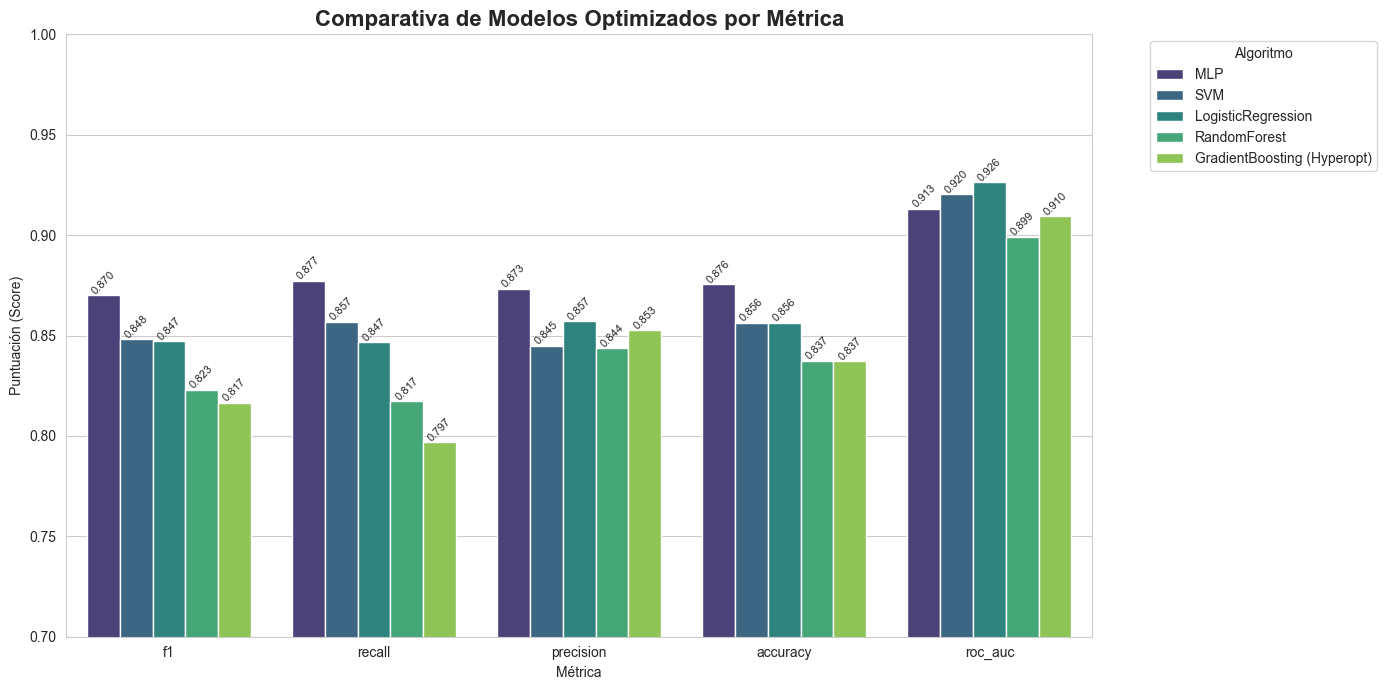

In [ ]:
# ANÁLISIS 2: COMPARATIVA MULTIMÉTRICA VISUAL

df_plot = df_final.melt(id_vars='Algoritmo', value_vars=metricas, var_name='Métrica', value_name='Valor')

plt.figure(figsize=(14, 7))
sns.set_style("whitegrid")
ax = sns.barplot(data=df_plot, x='Métrica', y='Valor', hue='Algoritmo', palette='viridis')

plt.ylim(0.7, 1.0) # Ajustamos el zoom para ver las diferencias
plt.title('Comparativa de Modelos Optimizados por Métrica', fontsize=16, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Algoritmo')
plt.ylabel('Puntuación (Score)')

# Añadir valores sobre las barras
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.3f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha = 'center', va = 'center', 
                xytext = (0, 9), 
                textcoords = 'offset points',
                fontsize=8, rotation=45)

plt.tight_layout()
plt.show()

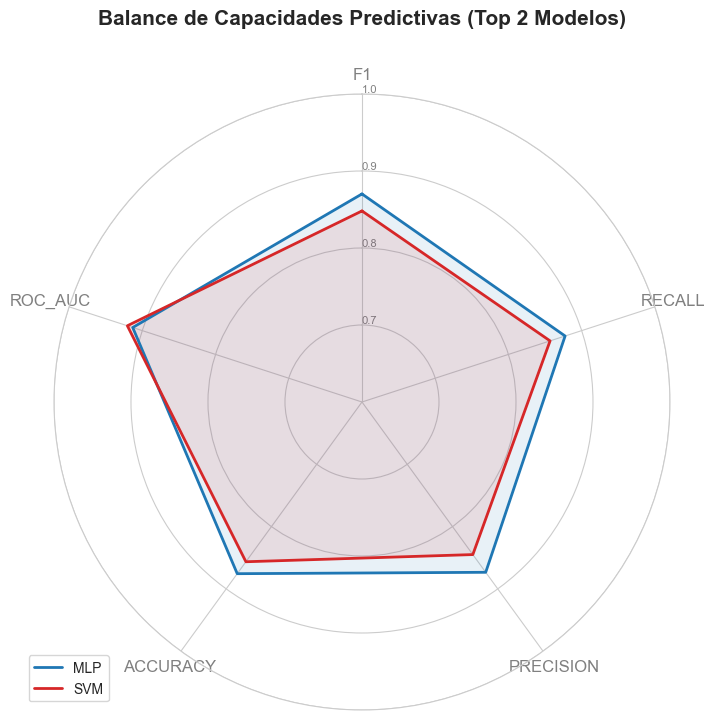

In [ ]:
# ANÁLISIS 3: RADAR CHART - EQUILIBRIO DEL TOP 2 (MODELOS GANADORES)

def make_radar_chart(df, modelos_indices):
    categories = [m.upper() for m in metricas]
    N = len(categories)
    
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    
    colors = ['#1f77b4', '#d62728']
    
    for i, idx in enumerate(modelos_indices):
        values = df.loc[idx, metricas].values.flatten().tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=2, linestyle='solid', label=df.loc[idx, 'Algoritmo'], color=colors[i])
        ax.fill(angles, values, color=colors[i], alpha=0.1)

    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)
    plt.xticks(angles[:-1], categories, color='grey', size=12)
    ax.set_rlabel_position(0)
    plt.yticks([0.7, 0.8, 0.9, 1.0], ["0.7","0.8","0.9","1.0"], color="grey", size=8)
    plt.ylim(0.6, 1.0)
    
    plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
    plt.title("Balance de Capacidades Predictivas (Top 2 Modelos)", size=15, fontweight='bold', y=1.1)
    plt.show()

# Graficamos los dos primeros del ranking
make_radar_chart(df_final, [0, 1])

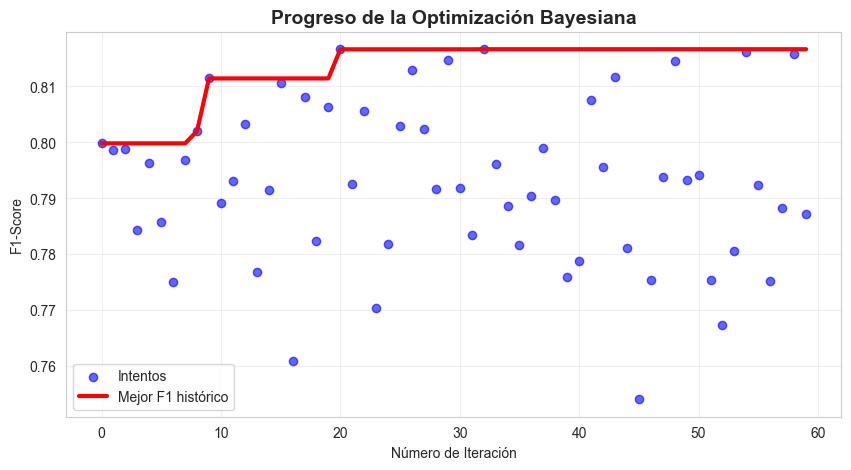

In [29]:
# ANÁLISIS 3: EVOLUCIÓN DE LA BÚSQUEDA (HYPEROPT)

plt.figure(figsize=(10, 5))

# Dibujamos cada intento
plt.scatter(range(len(df_hyp)), df_hyp['f1'], alpha=0.6, color='blue', label='Intentos')
# Línea del mejor resultado acumulado
plt.plot(df_hyp['f1'].expanding().max(), color='red', lw=3, label='Mejor F1 histórico')

plt.title('Progreso de la Optimización Bayesiana', fontsize=14, fontweight='bold')
plt.xlabel('Número de Iteración')
plt.ylabel('F1-Score')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Procesando: MLP...
Procesando: SVM...
Procesando: LogisticRegression...


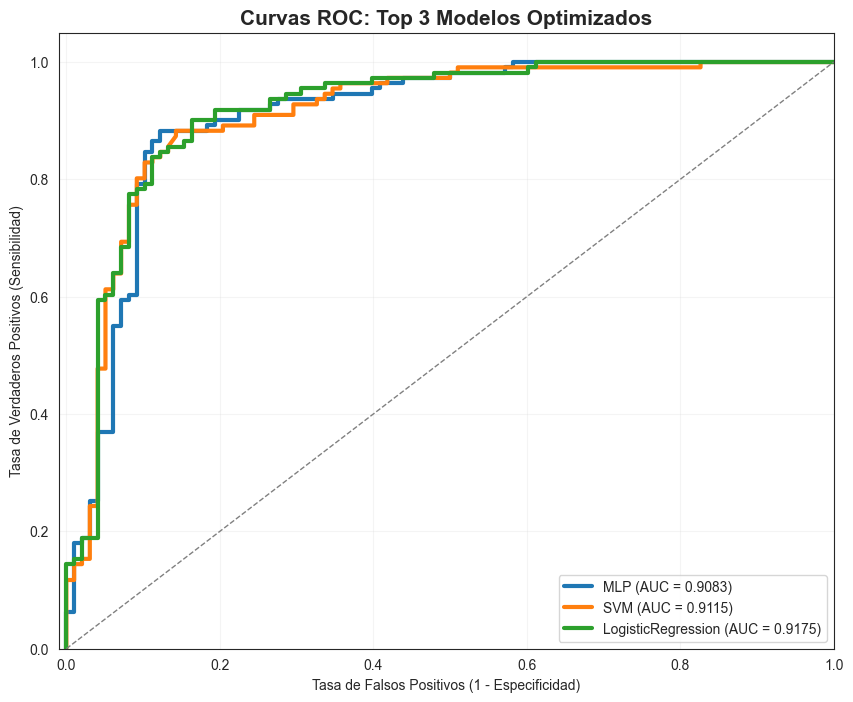

In [ ]:
# ANÁLISIS 4: CURVAS ROC

# 1. FUNCIÓN DE EXTRACCIÓN
def get_clean_params(df_resultados, algoritmo):
    row = df_resultados[df_resultados['Algoritmo'] == algoritmo].sort_values('mean_test_f1', ascending=False).iloc[0]
    params = {}
    
    for k, v in row.items():
        if k.startswith('param_') and pd.notnull(v):
            name = k.replace('param_', '')
            
            # Conversión específica según el nombre del parámetro
            # Parámetros que SIEMPRE deben ser enteros
            if name in ['n_estimators', 'max_depth', 'min_samples_leaf', 'min_samples_split']:
                params[name] = int(float(v))
            
            # Parámetros que SIEMPRE deben ser flotantes (como learning_rate)
            elif name in ['learning_rate_init', 'alpha', 'C', 'gamma', 'learning_rate', 'subsample']:
                try:
                    params[name] = float(v)
                except ValueError: # Caso de 'scale' o 'auto' en gamma
                    params[name] = v
            
            # Manejo de tuplas para MLP
            elif name == 'hidden_layer_sizes':
                params[name] = ast.literal_eval(str(v))
            
            # Resto de parámetros (strings como 'rbf', 'relu', etc.)
            else:
                params[name] = v
    return params

# 2. SELECCIÓN DE LOS TOP 3
top_3_nombres = df_final.head(3)['Algoritmo'].tolist()

plt.figure(figsize=(10, 8))
sns.set_style("white")

# 3. BUCLE DE GENERACIÓN
for nombre in top_3_nombres:
    print(f"Procesando: {nombre}...")
    
    if 'GradientBoosting' in nombre:
        best_gb = df_hyp.sort_values('f1', ascending=False).iloc[0]
        model = GradientBoostingClassifier(
            n_estimators=int(best_gb['n_estimators']),
            learning_rate=float(best_gb['learning_rate']),
            max_depth=int(best_gb['max_depth']),
            subsample=float(best_gb['subsample']),
            min_samples_split=int(best_gb['min_samples_split']),
            random_state=42
        )
    elif 'SVM' in nombre:
        model = SVC(**get_clean_params(df_grid, 'SVM'), probability=True, random_state=42)
    elif 'RandomForest' in nombre:
        model = RandomForestClassifier(**get_clean_params(df_grid, 'RandomForest'), random_state=42)
    elif 'MLP' in nombre:
        model = MLPClassifier(**get_clean_params(df_grid, 'MLP'), random_state=42, max_iter=1000)
    elif 'LogisticRegression' in nombre:
        model = LogisticRegression(**get_clean_params(df_grid, 'LogisticRegression'), random_state=42, max_iter=1000)

    # Evaluación mediante CV
    y_probas = cross_val_predict(model, X_proc, y_opt, cv=skf, method='predict_proba')
    fpr, tpr, _ = roc_curve(y_opt, y_probas[:, 1], pos_label=2)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=3, label=f'{nombre} (AUC = {roc_auc:.4f})')

# 4. ESTÉTICA
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
plt.title('Curvas ROC: Top 3 Modelos Optimizados', fontsize=15, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.show()

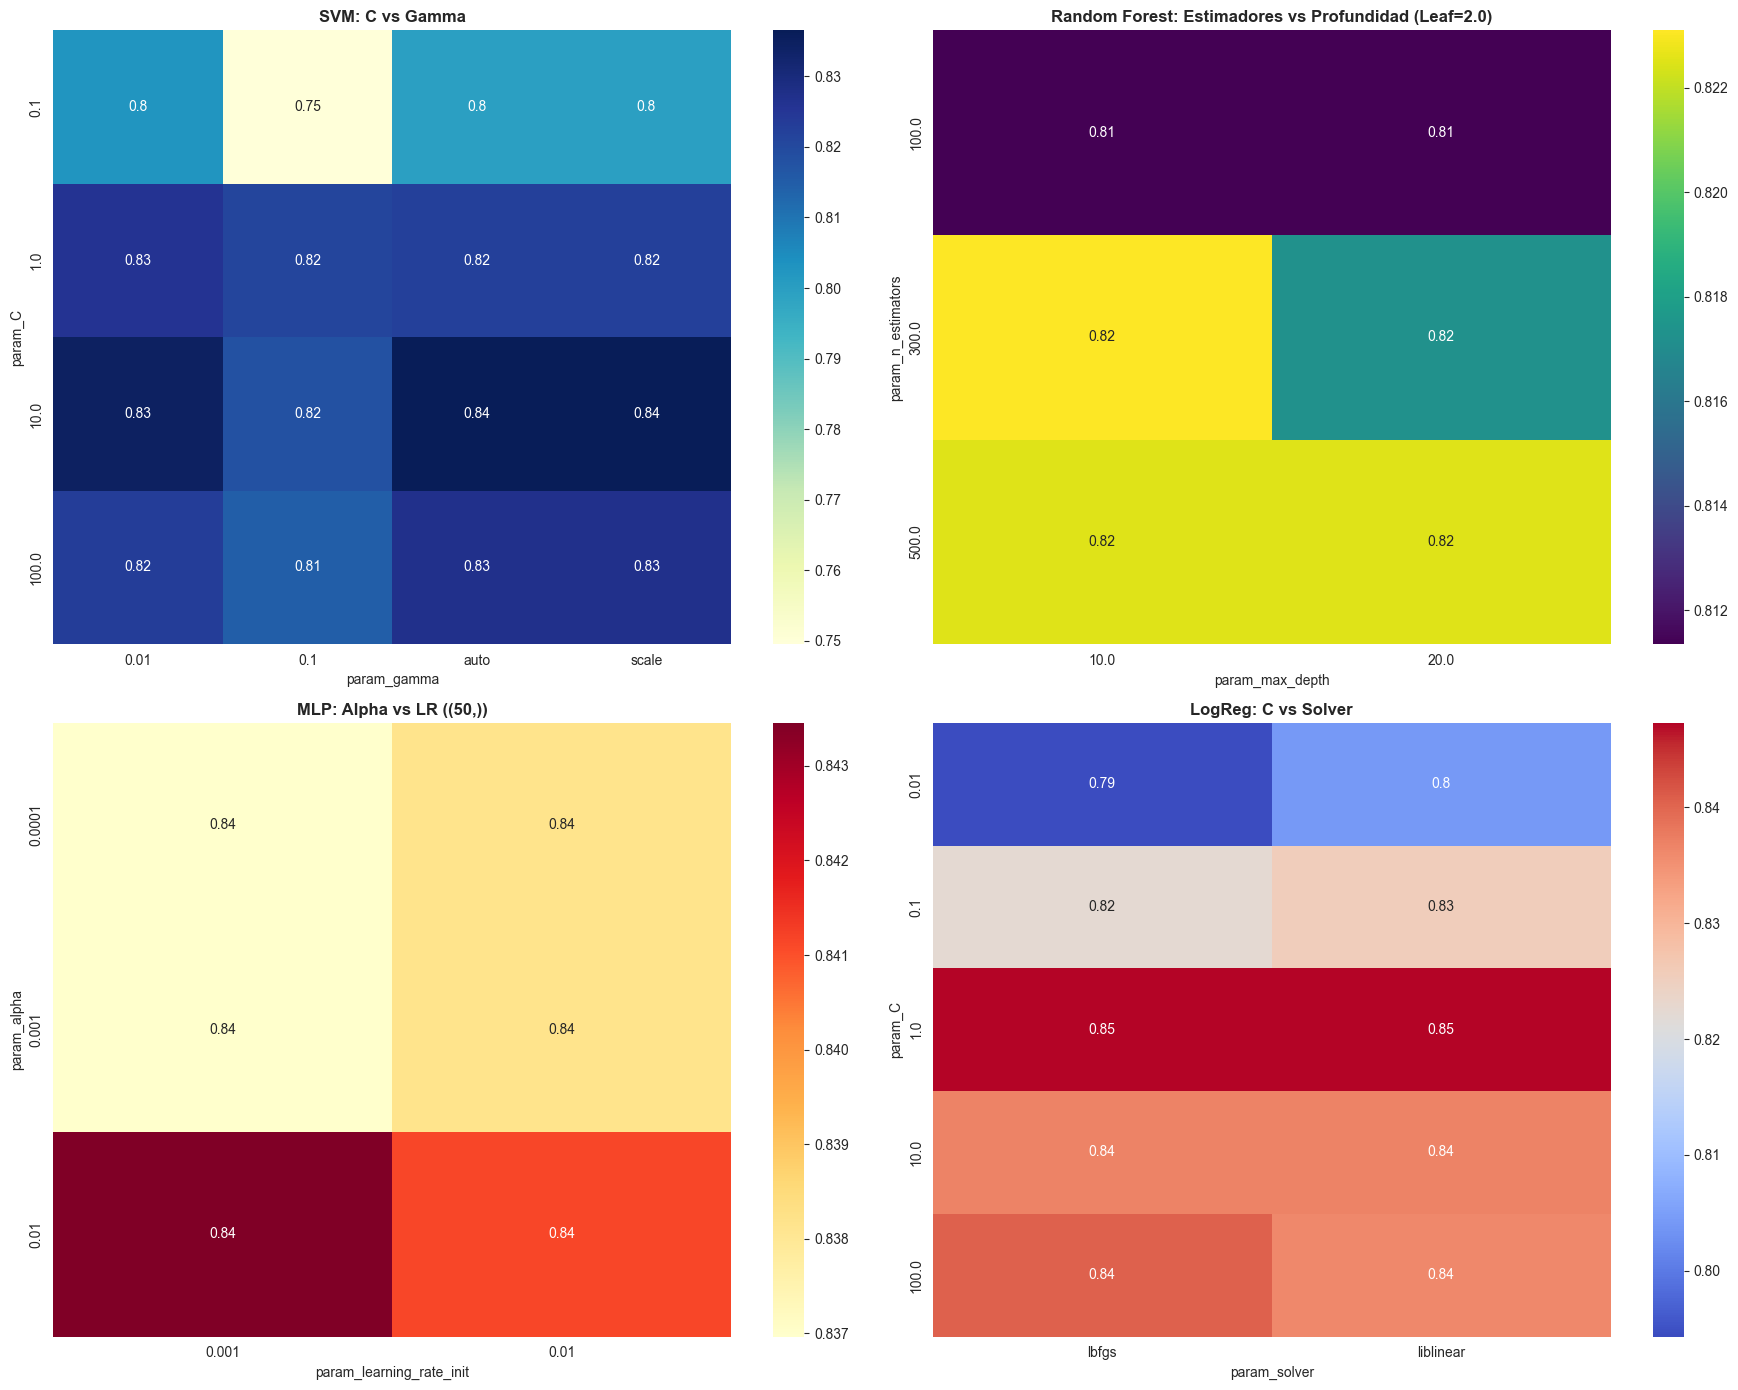

In [ ]:
# ANÁLISIS 5: MAPAS DE CALOR - SENSIBILIDAD DE TODOS LOS MODELOS

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

# 1. SVM: C vs Gamma
df_svm = df_grid[df_grid['Algoritmo'] == 'SVM']
pivot_svm = df_svm.pivot_table(index='param_C', columns='param_gamma', values='mean_test_f1')
sns.heatmap(pivot_svm, annot=True, cmap='YlGnBu', ax=axes[0])
axes[0].set_title('SVM: C vs Gamma', fontweight='bold')

# 2. Random Forest: n_estimators vs max_depth (Fijando min_samples_leaf)
df_rf = df_grid[df_grid['Algoritmo'] == 'RandomForest']
best_leaf = df_rf.sort_values('mean_test_f1', ascending=False).iloc[0]['param_min_samples_leaf']
df_rf_sub = df_rf[df_rf['param_min_samples_leaf'] == best_leaf]
pivot_rf = df_rf_sub.pivot_table(index='param_n_estimators', columns='param_max_depth', values='mean_test_f1')
sns.heatmap(pivot_rf, annot=True, cmap='viridis', ax=axes[1])
axes[1].set_title(f'Random Forest: Estimadores vs Profundidad (Leaf={best_leaf})', fontweight='bold')

# 3. MLP: Alpha vs Learning Rate (Fijando arquitectura)
df_mlp = df_grid[df_grid['Algoritmo'] == 'MLP']
best_layer = df_mlp.sort_values('mean_test_f1', ascending=False).iloc[0]['param_hidden_layer_sizes']
df_mlp_sub = df_mlp[df_mlp['param_hidden_layer_sizes'] == best_layer]
pivot_mlp = df_mlp_sub.pivot_table(index='param_alpha', columns='param_learning_rate_init', values='mean_test_f1')
sns.heatmap(pivot_mlp, annot=True, cmap='YlOrRd', ax=axes[2])
axes[2].set_title(f'MLP: Alpha vs LR ({best_layer})', fontweight='bold')

# 4. Regresión Logística: C vs Solver
df_lr = df_grid[df_grid['Algoritmo'] == 'LogisticRegression']
pivot_lr = df_lr.pivot_table(index='param_C', columns='param_solver', values='mean_test_f1')
sns.heatmap(pivot_lr, annot=True, cmap='coolwarm', ax=axes[3])
axes[3].set_title('LogReg: C vs Solver', fontweight='bold')

plt.tight_layout()
plt.show()

Evaluando el Modelo Ganador: MLP (F1: 0.8702)


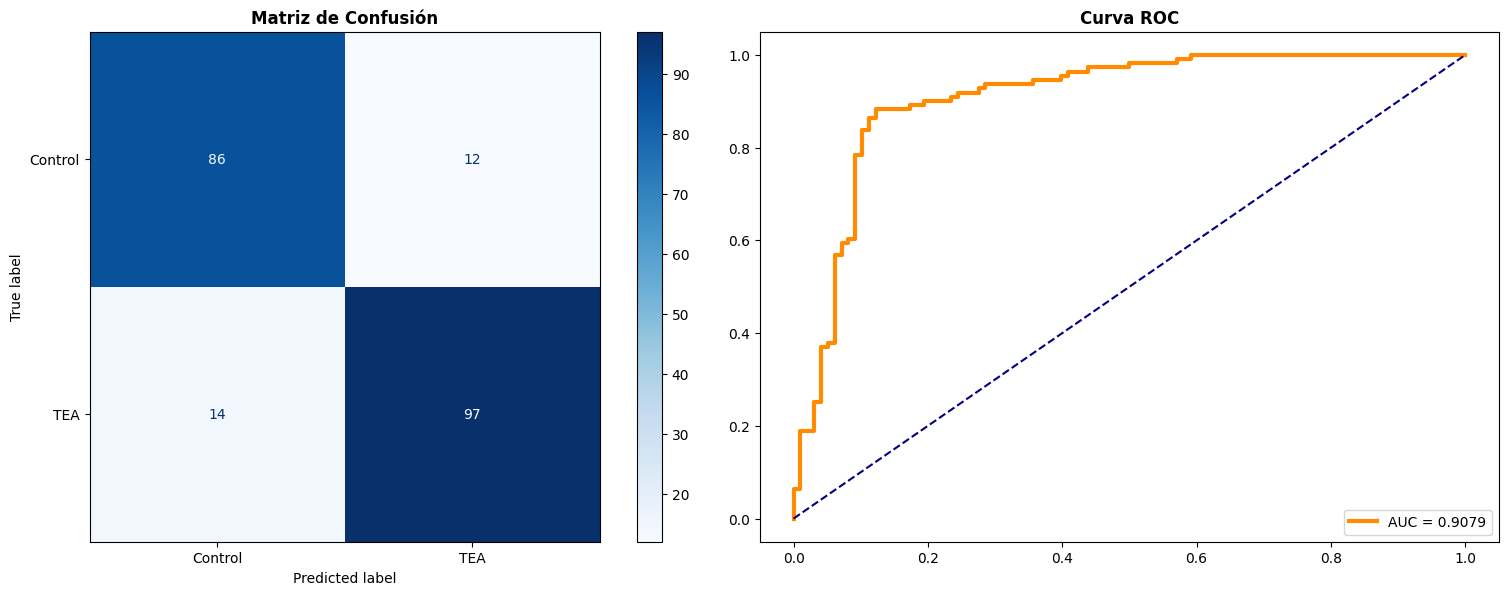

REPORTE DE CLASIFICACIÓN:
              precision    recall  f1-score   support

     Control       0.86      0.88      0.87        98
         TEA       0.89      0.87      0.88       111

    accuracy                           0.88       209
   macro avg       0.87      0.88      0.88       209
weighted avg       0.88      0.88      0.88       209



In [ ]:
# 1. INSTANCIACIÓN DEL MODELO GANADOR
# Subimos max_iter a 2000 para eliminar los ConvergenceWarning
modelo_final = MLPClassifier(
    hidden_layer_sizes=(50,),
    activation='tanh',
    alpha=0.01,
    learning_rate_init=0.001,
    max_iter=2000, 
    random_state=42
)

print(f"Evaluando el Modelo Ganador: MLP (F1: 0.8702)")

# 2. PREDICCIONES (Validación Cruzada)
y_pred = cross_val_predict(modelo_final, X_proc, y_opt, cv=skf)
y_probas = cross_val_predict(modelo_final, X_proc, y_opt, cv=skf, method='predict_proba')

# 3. VISUALIZACIÓN
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# A. Matriz de Confusión
ConfusionMatrixDisplay.from_predictions(
    y_opt, y_pred, display_labels=['Control', 'TEA'], 
    cmap='Blues', ax=ax[0]
)
ax[0].set_title('Matriz de Confusión', fontweight='bold')

# B. Curva ROC
fpr, tpr, _ = roc_curve(y_opt, y_probas[:, 1], pos_label=2)
ax[1].plot(fpr, tpr, color='darkorange', lw=3, label=f'AUC = {auc(fpr, tpr):.4f}')
ax[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
ax[1].set_title('Curva ROC', fontweight='bold')
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# 4. REPORTE FINAL
print("REPORTE DE CLASIFICACIÓN:")
print(classification_report(y_opt, y_pred, target_names=['Control', 'TEA']))